# Anforderungen
1. kurze explorative Datenanalyse des Datensatzes mit Visualisierung
2. Identifizierung und Begründung der notwendigen Schritte der Datenaufbereitung, beispielsweise Umgang mit fehlenden Werten, Ausreißern, kategorialen Merkmalen oder unterschiedlichen Merkmalsskalen.
3. Angemessene Aufteilung der Daten in Abhängigkeit der gewählten Methoden
4. Pro Klassifikationsmethode ist je mindestens ein Hyperparameter zu variieren, idealerweise ist eine Hyperparameteroptimierung durchzuführen
5. Begründung der Auswahl des variierten Hyperparameters und der untersuchten Hyperparametereinstellungen
6. Bewertung mit der Klassifikationsleistung anhand geeigneter Qualitätsmaßen. Die Wahl der Qualitätsmaße ist zu begründen
7. Angemessene Visualisierung insbesondere der Endergebnisse
8. Diskussion der Ergebnisse inkl. eines Vergleichs der Methoden

# 1. Datensatz und explorative Analyse

Ausgewählter Datensatz – [Fashion MNIST](https://github.com/zalandoresearch/fashion-mnist): ein Datensatz mit Artikelbildern von Zalando, bestehend aus einem Trainingssatz mit 60 000 Beispielen und einem Testsatz mit 10 000 Beispielen. Jedes Beispiel ist ein 28×28-Graustufenbild, das einer von 10 Klassen zugeordneten Klassifizierung zugeordnet ist.

Der Datensatz stellt eine komplexere Klassifikationsaufgabe für Computer-Vision Modelle dar. Es muss anhand des Bildes eine korrekte Klasse aus 10 ausgewählt werden.

Im Folgenden wird der Datensatz analysiert, um folgende Eigenschaften zu bestimmen:
- Anzahl an Bildern in Training- und Test-Set.
- Verteilung der Klassen in Training- und Test-Set.
- Generalisierte Darstellung jeder Klasse.
- Pixel-Werte und -Dichten pro Klasse.

Anschließend werden auch die Beispiel-Bilder jeder Klasse dargestellt.

In [5]:
'''
Datensatz durch PyTorch's Torchvision laden
'''

import torchvision


fashion_mnist_train = torchvision.datasets.FashionMNIST(
        root="./data",
        train=True,
        download=True
    )

fashion_mnist_test = torchvision.datasets.FashionMNIST(
        root="./data",
        train=False,
        download=True
    )

# Globale Variable, die Klassen im Datensatz [0, ..., 9] zu textuellen Beschreibungen mappt.
FASHION_CLASSES = (
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
)

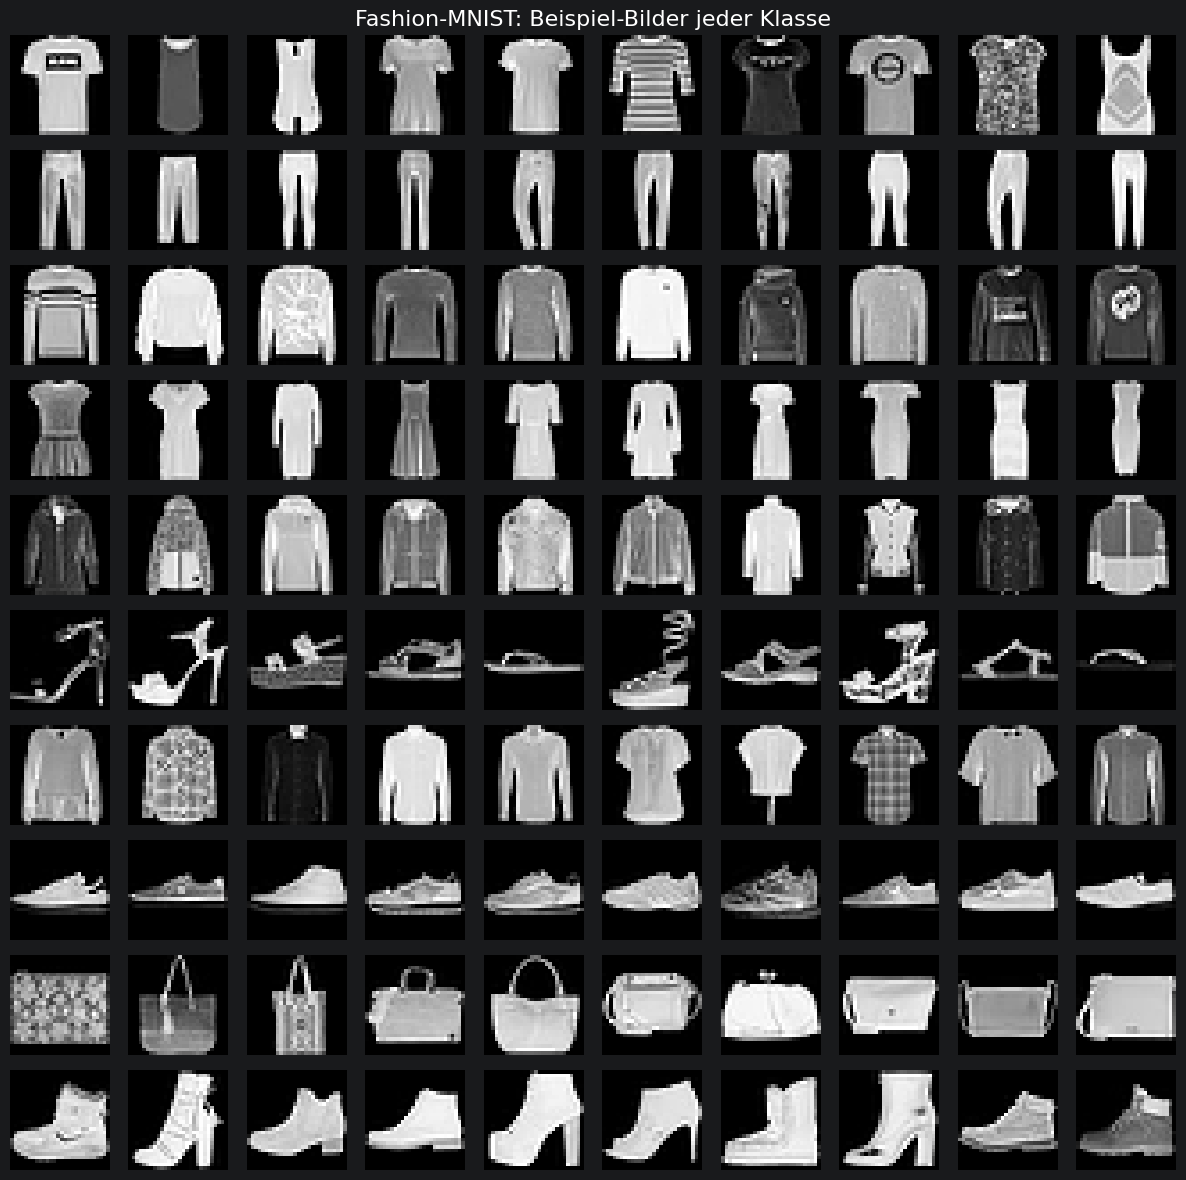

In [7]:
"""
Beispiel-Bilder jeder Klasse mit Matplotlib zeichnen.
"""

from matplotlib import pyplot as plt
import numpy as np

def plot_samples(dataset, classes):
    fig, axes = plt.subplots(10, 10, figsize=(12, 12))

    for class_idx in range(10):
        # Erste 10 Beispiele der jeweiligen Klasse finden
        indices = np.where(
            np.asarray(dataset.targets) == class_idx
        )[0][:10]

        # Jedes Bild in Graustufen zeichnen
        for col, idx in enumerate(indices):
            image, label = dataset[idx]

            axes[class_idx, col].imshow(image, cmap="gray")
            axes[class_idx, col].axis("off")

            if col == 0:
                axes[class_idx, col].set_ylabel(
                    classes[class_idx],
                    rotation=0,
                    labelpad=45,
                    va="center"
                )

    plt.suptitle(
        "Fashion-MNIST: Beispiel-Bilder jeder Klasse",
        fontsize=16
    )
    plt.tight_layout()
    plt.show()

plot_samples(fashion_mnist_train,FASHION_CLASSES)


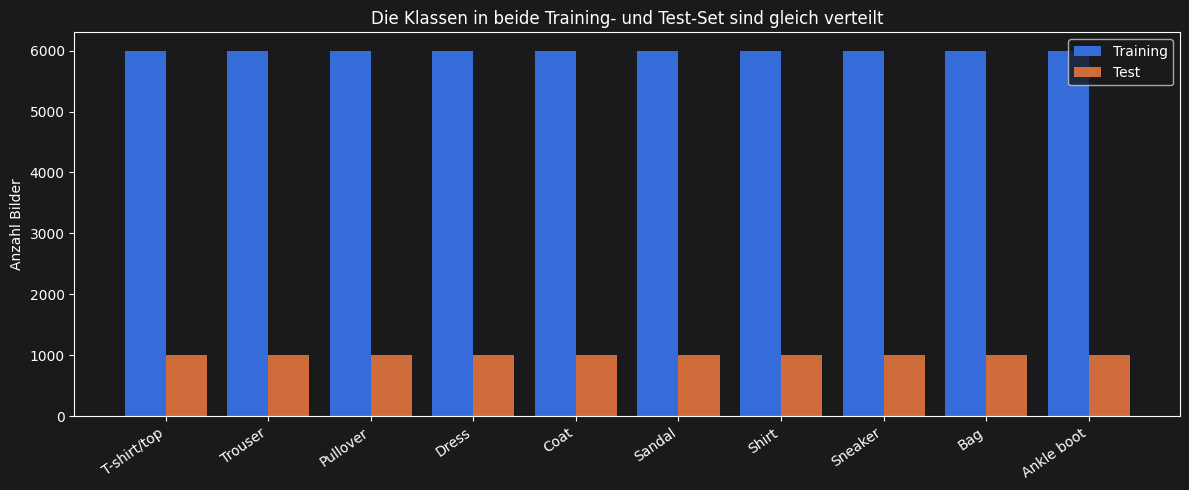

In [11]:
"""
Verteilung der Klassen in Test- und Training-Set zeigen
"""

def class_distribution(test_set, train_set, classes):
    train_labels = np.asarray(train_set.targets)
    test_labels = np.asarray(test_set.targets)

    train_counts = np.bincount(train_labels, minlength=10)
    test_counts = np.bincount(test_labels, minlength=10)

    x = np.arange(len(classes))
    width = 0.4

    plt.figure(figsize=(12, 5))

    plt.bar(x - width / 2, train_counts, width, label="Training")
    plt.bar(x + width / 2, test_counts, width, label="Test")

    plt.xticks(x, classes, rotation=35, ha="right")
    plt.ylabel("Anzahl Bilder")
    plt.title("Die Klassen in beide Training- und Test-Set sind gleich verteilt")
    plt.legend()
    plt.tight_layout()
    plt.show()

class_distribution(test_set=fashion_mnist_test, train_set=fashion_mnist_train, classes=FASHION_CLASSES)

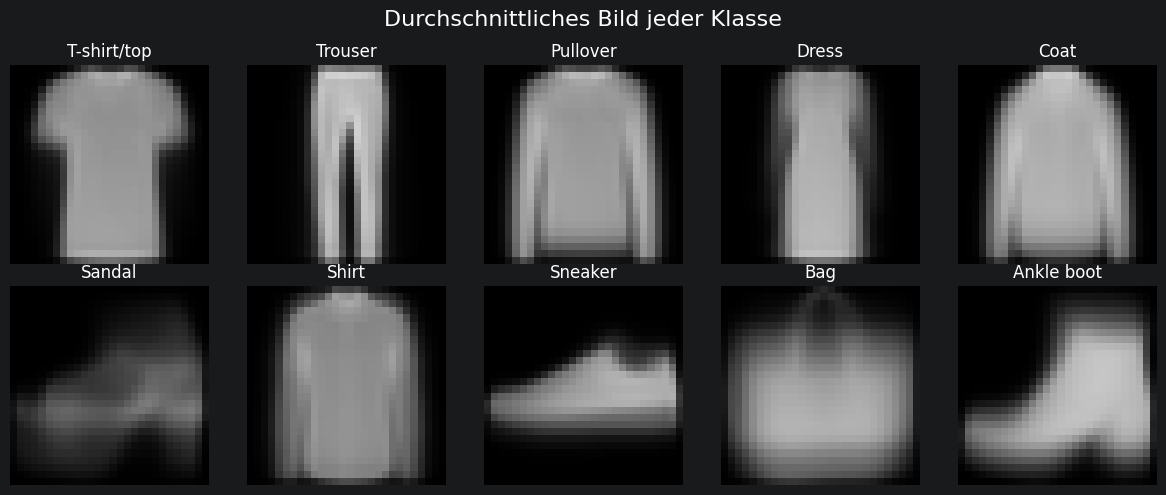

In [12]:
"""
Durchschnittliche Bilder jeder Klasse zeichnen
"""
def plot_mean_image(dataset, classes):
    labels = np.asarray(dataset.targets)
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))

    for class_idx, ax in enumerate(axes.flat):
        class_images = dataset.data[
            labels == class_idx
            ].float()

        mean_image = class_images.mean(dim=0)

        ax.imshow(mean_image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(classes[class_idx])
        ax.axis("off")

    plt.suptitle("Durchschnittliches Bild jeder Klasse", fontsize=16)
    plt.tight_layout()
    plt.show()

plot_mean_image(fashion_mnist_train, FASHION_CLASSES)

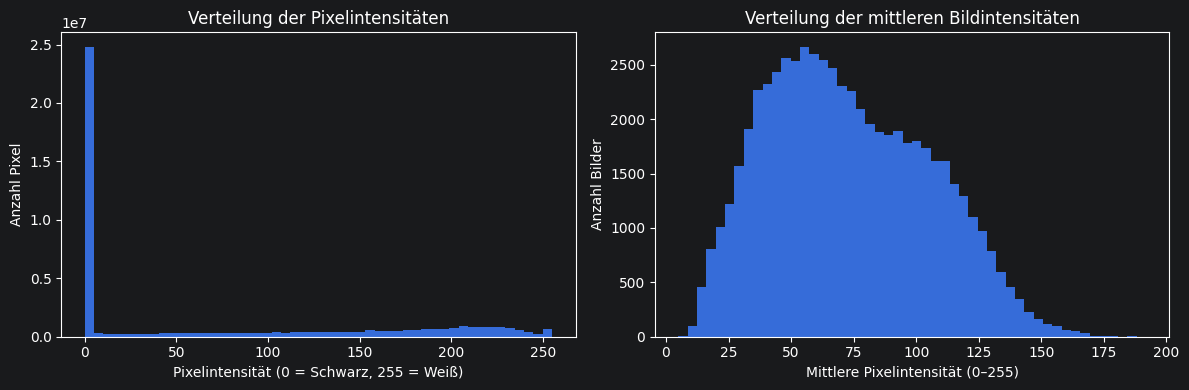

In [17]:
"""
Es werden zwei Verteilungen visualisiert:
    1. Verteilung aller Pixelintensitäten:
       Zeigt, wie häufig bestimmte Helligkeitswerte im gesamten Datensatz
       vorkommen. Ein hoher Anteil niedriger Werte bedeutet, dass viele
       Pixel dunkel bzw. schwarz sind.

    2. Verteilung der mittleren Pixelintensitäten pro Bild:
       Für jedes Bild wird der Durchschnitt seiner 784 Pixelwerte berechnet.
       Das Histogramm zeigt, wie sich die durchschnittliche Helligkeit
       zwischen den einzelnen Bildern verteilt.
"""

def plot_intensity(dataset):
    # die Bilder in Float-Werte konvertieren
    images = dataset.data.float()

    # Mittlere Pixelintensität pro Bild
    mean_intensity = images.mean(dim=(1, 2)).numpy()

    # Alle Pixelintensitäten zu einem eindimensionalen Array zusammenfassen
    pixel_values = images.numpy().ravel()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(pixel_values, bins=50)
    axes[0].set_xlabel("Pixelintensität (0 = Schwarz, 255 = Weiß)")
    axes[0].set_ylabel("Anzahl Pixel")
    axes[0].set_title("Verteilung der Pixelintensitäten")

    axes[1].hist(mean_intensity, bins=50)
    axes[1].set_xlabel("Mittlere Pixelintensität (0–255)")
    axes[1].set_ylabel("Anzahl Bilder")
    axes[1].set_title("Verteilung der mittleren Bildintensitäten")

    plt.tight_layout()
    plt.show()

plot_intensity(fashion_mnist_train)